# Week 2 Linear Regression with Lasso, Ridge and Elastic Net Regression

### The overall project examines diabetes related health and hospital outcomes, for week 2 I'm using the Hospital dataset which contains encounters for patients with diabetes and their 30-day readmission rates, Week 2 specifically focuses on linear regression with Lasso, Ridge and Elastic Net therefore time_in_hospital as a continous response variable will be used for this exercise. This allows ordinary Linear Regression, Ridge, Lasso and Elastic Net to be compared appropriately while keeping the analysis within the same diabetic patient population.

## Dataset: US 130 Hospital Diabetes encounter readmission rate

## Import Libraries and load dataset

In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
# 2. Load the hospital diabetes dataset
hospital_url = (
    "https://raw.githubusercontent.com/"
    "jeganart/hospitaldatasetmilestone3/refs/heads/main/"
    "diabetic_data.csv"
)

df = pd.read_csv(hospital_url)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Outcome and Predictors
time_in_hospital is the continous outcome for week 2 regression exercise, the predictors describe hospital utilization and clinial activity, the categorical readmitted variable is intentionally not used as the outcome here but for later weeks we will use that for classification methods.

In [3]:
# 3. Select variables
target = "time_in_hospital"
features = [
    "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient",
    "number_diagnoses"
]

model_df = df[features + [target]].dropna().copy()
print("Rows used:", len(model_df))
display(model_df.describe().T)


Rows used: 101766


,count,mean,std,min,25%,50%,75%,max
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0


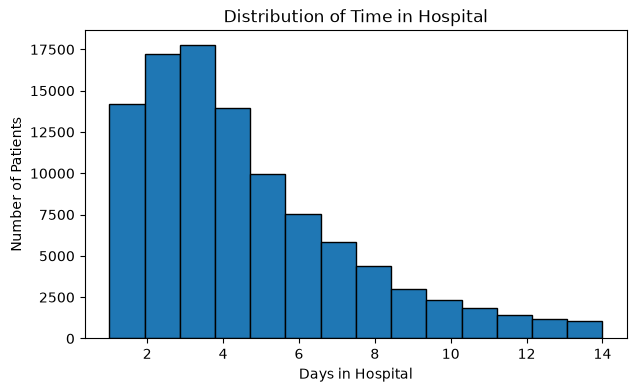

In [4]:
# Distribution of time in hospital, let's examine the distribution of hospital stay durations, this provides context for the continuous target variable in our analysis.

plt.figure(figsize=(7, 4))
plt.hist(model_df["time_in_hospital"], bins=14, edgecolor="black")
plt.xlabel("Days in Hospital")
plt.ylabel("Number of Patients")
plt.title("Distribution of Time in Hospital")
plt.show()


### Train/Test Split and Scaling
Regularization penalizes the coefficient size, so the predictors are standardized before fitting the model, the scaler is fit only o the training data to avoid data leakage.

In [5]:
# 4. Split and scale
X = model_df[features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))


Training rows: 81412
Test rows: 20354


### Baseline Linear Regression
Ordinary linear regression provides the baseline for determining whether regularization improves prediction


In [6]:
# 5. Linear Regression
linear = LinearRegression()
linear.fit(X_train_scaled, y_train)
pred_linear = linear.predict(X_test_scaled)

rmse_linear = np.sqrt(mean_squared_error(y_test, pred_linear))
mae_linear = mean_absolute_error(y_test, pred_linear)
r2_linear = r2_score(y_test, pred_linear)

print("RMSE:", rmse_linear)
print("MAE:", mae_linear)
print("R-squared:", r2_linear)


RMSE: 2.522637531387741
MAE: 1.9251166678304488
R-squared: 0.2688827201010452


### Ridge Regression
Ridge uses L2 regularization, It shrinks coefficients toward zero but generally retains all predictors, Cross valiation selects the regularization strength (alpha)

In [7]:
# 6. Ridge Regression
alphas = np.logspace(-4, 4, 50)
ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train_scaled, y_train)
pred_ridge = ridge.predict(X_test_scaled)

rmse_ridge = np.sqrt(mean_squared_error(y_test, pred_ridge))
mae_ridge = mean_absolute_error(y_test, pred_ridge)
r2_ridge = r2_score(y_test, pred_ridge)

print("Best alpha:", ridge.alpha_)
print("RMSE:", rmse_ridge)
print("MAE:", mae_ridge)
print("R-squared:", r2_ridge)

Best alpha: 16.768329368110066
RMSE: 2.522636678848878
MAE: 1.925125289100658
R-squared: 0.26888321427096173


### Lasso Regression

Lasso uses L1 regularization. It shrinks coefficients and can reduce weaker coefficients to exactly zero, so it can also perform feature selection

In [8]:
# 7. Lasso Regression
lasso = LassoCV(alphas=alphas, cv=5, max_iter=10000)
lasso.fit(X_train_scaled, y_train)
pred_lasso = lasso.predict(X_test_scaled)

rmse_lasso = np.sqrt(mean_squared_error(y_test, pred_lasso))
mae_lasso = mean_absolute_error(y_test, pred_lasso)
r2_lasso = r2_score(y_test, pred_lasso)

print("Best alpha:", lasso.alpha_)
print("RMSE:", rmse_lasso)
print("MAE:", mae_lasso)
print("R-squared:", r2_lasso)


Best alpha: 0.0001
RMSE: 2.5226368878002403
MAE: 1.9251196751693809
R-squared: 0.268883093153358


### Elastic Net Regression

Elastic Net combines L1 and L2 regularization, providing a compromise between Lasso's feature selection behavior and Ridge's coefficient shrinkage.

In [9]:
# 8. Elastic Net Regression
elastic = ElasticNetCV(
    alphas=alphas, l1_ratio=[0.1, 0.5, 0.9], cv=5, max_iter=10000
)
elastic.fit(X_train_scaled, y_train)
pred_elastic = elastic.predict(X_test_scaled)

rmse_elastic = np.sqrt(mean_squared_error(y_test, pred_elastic))
mae_elastic = mean_absolute_error(y_test, pred_elastic)
r2_elastic = r2_score(y_test, pred_elastic)

print("Best alpha:", elastic.alpha_)
print("Best l1 ratio:", elastic.l1_ratio_)
print("RMSE:", rmse_elastic)
print("MAE:", mae_elastic)
print("R-squared:", r2_elastic)


Best alpha: 0.00021209508879201905
Best l1 ratio: 0.1
RMSE: 2.5226366036739503
MAE: 1.925125295309868
R-squared: 0.2688832578457271


## Model Comparison

Lower RMSE and MAE indicates smaller Prediction Errors, while higher R-squared indicates greater explained variation

,Model,RMSE,MAE,R-squared
0,Linear Regression,2.5226,1.9251,0.2689
1,Ridge,2.5226,1.9251,0.2689
2,Lasso,2.5226,1.9251,0.2689
3,Elastic Net,2.5226,1.9251,0.2689


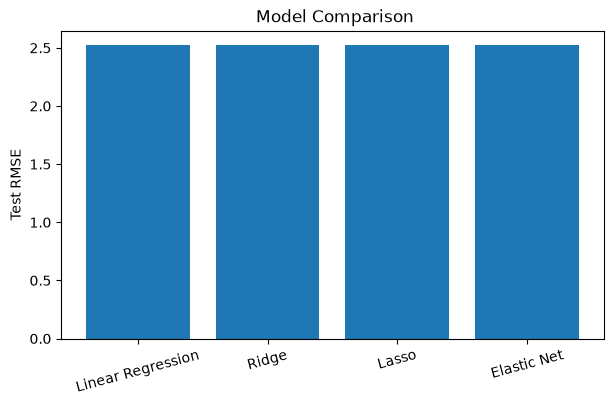

In [10]:
# 9. Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "Lasso", "Elastic Net"],
    "RMSE": [rmse_linear, rmse_ridge, rmse_lasso, rmse_elastic],
    "MAE": [mae_linear, mae_ridge, mae_lasso, mae_elastic],
    "R-squared": [r2_linear, r2_ridge, r2_lasso, r2_elastic]
})

display(results.round(4))

plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["RMSE"])
plt.ylabel("Test RMSE")
plt.title(" Model Comparison")
plt.xticks(rotation=15)
plt.show()

### All four models produced nearly identical predictive performance, with RMSE approximately 2.523, MAE approximately 1.925 and R-squared approximately 0.268. Elastic Net had the numerically highest R-squared 0.26888325, but the difference from the ordinary Linear Regression of 0.2688827 was negligible, therefore there is no meaningful evidence that regularization improved prediction in this analysis.

### Effects of Regulariztion on coefficients

The coefficient comparison shows what regularization is doing not just whether prediction changed, Ridge should shrink coefficients while retaining predictors, Lasso may reduce weaker coefficients to zero and Elastic Net combines both behaviors 

In [11]:
# 10. Compare coefficients
coefficients = pd.DataFrame({
    "Feature": features,
    "Linear": linear.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "Elastic Net": elastic.coef_
})

display(coefficients.round(4))
print("Lasso coefficients reduced to zero:", np.sum(np.isclose(lasso.coef_, 0)))


,Feature,Linear,Ridge,Lasso,Elastic Net
0,num_lab_procedures,0.5959,0.5958,0.5958,0.5958
1,num_procedures,0.0882,0.0883,0.0881,0.0883
2,num_medications,1.1268,1.1266,1.1268,1.1266
3,number_outpatient,-0.1002,-0.1002,-0.1001,-0.1002
4,number_emergency,-0.0857,-0.0857,-0.0856,-0.0857
5,number_inpatient,0.1266,0.1266,0.1265,0.1266
6,number_diagnoses,0.2727,0.2727,0.2726,0.2727


Lasso coefficients reduced to zero: 0


### Coefficients comparison Plot

Regularization works by shrinking regression coefficients, this plot provides a direct visual comparison of how Linear Regression, Ridge, Lasso and Elastic Net treat the same predictors.

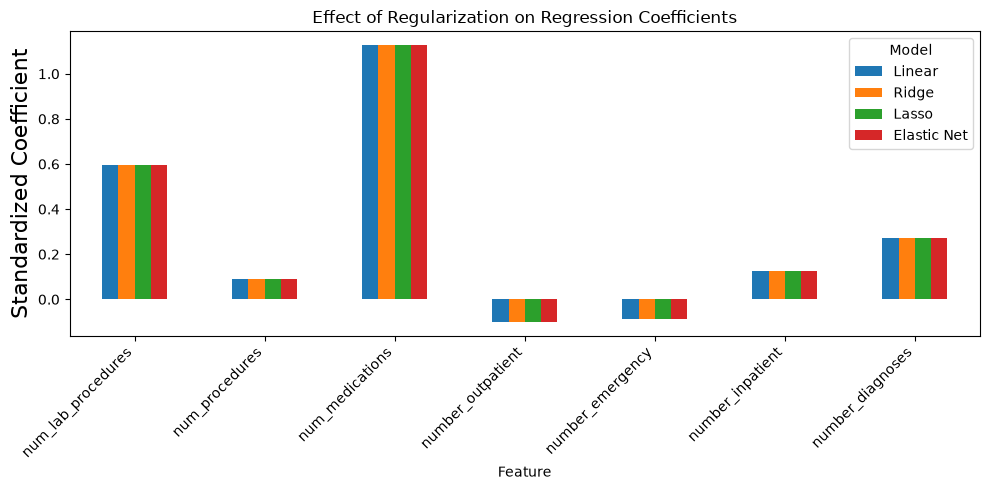

In [12]:
# Plot coefficients across our four models

coef_plot = coefficients.set_index("Feature")

coef_plot.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Standardized Coefficient", fontsize=16)
plt.title("Effect of Regularization on Regression Coefficients")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()


## Summary

The coefficient resutls support the conclusion that regularization didn't improve the prediction in this analysis. Ridge, Lasso and Elastic Net produced coefficients that were almost identical to ordinary Linear Regression and Lasso reduced zero predictors to a coefficient of zero. Among the standardized predictors, **num_medications** had the largest positice coefficient at approximately 1.13, followed by **num_lab_procedures** at approximately 0.60 and **number_diagnoses** at approximately 0.27. These results indicate associations with longer hospital stays within this model.. They should be interpreted as causal effects.

Important finding from this week is regularization doesn't automatically improve a model. Ridge, Lasso and Elastic Net are useful for controlling model complexity and reducing overfitting, but in this dataset they provided almost no advantage over ordinary Linear Regression. The R-squared of approximately 0.269 means that the selected predictors explain only about **27% of the variation in time in hospital** leaving substantial variation unexplained. This suggests that the main limiations is not excessive coefficient size or overfitting but additional clinical or patient level information may be needed to better explain hosptial length of stay. More complex modeling method does not necessarily produce a better result. In this case Linear Regression model performed essentially as well as the regularization alternatives.